# Net-zero portfolio optimization and results

Worked equity and bond optimization followed by precomputed stock-level results. The stock-level input-data limitations are documented in Part 2.

Run the notebook from top to bottom. Local section numbers are retained within each part.

1. [11h: Net-zero tracking-error optimization](#part-11h)
2. [11i: Net-zero stock-level results](#part-11i)


In [1]:
import numpy as np
import pandas as pd
from quanttoolbox.optim.l1_minimize import minimize_l1_objective
from quanttoolbox.optim.quadprog import solve_qp
from quanttoolbox.portfolio.tracking_error import minimum_te_portfolio
import scipy.io as sio
import matplotlib.pyplot as plt
from scipy.interpolate import UnivariateSpline

<a id="part-11h"></a>

## Part 1 — 11h: Net-zero tracking-error optimization

The same 8-asset toy universes from `11a`/`11b`, now re-optimized at a
sequence of CI-reduction *targets* that trace out a CTB-style
compounding glide path ($R_{-}=30\%$ initial cut, $\Delta R=7\%$/year)
rather than an arbitrary grid. The equity case reuses `11a`'s
`min_te_portfolio` QP; the bond case reuses `11b`'s LP-reformulation
approach, extended with a duration-neutrality constraint. Two further
sections add a green-intensity floor and a carbon-momentum ceiling on
top of the CI-reduction target, for both the equity and bond cases.


In [2]:
def min_te_portfolio(b, Sigma, A_eq, b_eq, A_ub=None, b_ub=None, lb=None, ub=None):
    # gamma=0 case of the tracking-error minimization from 11a. Delegates to
    # quanttoolbox's minimum_te_portfolio (cvxpy/solve_qp-backed), which raises
    # RuntimeError on infeasible/non-convergent inputs by default -- this
    # notebook instead wants the old local behavior of settling at the nearest
    # feasible point (relied on by the intentionally-infeasible glide-path
    # points in section 3 below, which have no exception handling), so
    # on_infeasible="nearest" is used, which replicates that SLSQP fallback
    # (including the rank-deficient-row pruning this notebook used to do
    # locally via its own _prune_redundant_rows) internally. lb/ub of None are
    # passed through as 0.0/1.0 explicitly to match this function's own
    # historical defaults, since minimum_te_portfolio does not default them
    # the same way.
    lb = 0.0 if lb is None else lb
    ub = 1.0 if ub is None else ub
    result = minimum_te_portfolio(
        b,
        Sigma,
        a_eq=A_eq,
        b_eq=b_eq,
        c_ineq=A_ub,
        d_ineq=b_ub,
        lb=lb,
        ub=ub,
        on_infeasible="nearest",
    )
    return result.weights, result.tracking_error


def glide_path(R_minus, Delta_R, t0, offsets, prepend_zero=True):
    # R(t) = 1 - (1-R_minus)*(1-Delta_R)^(t-t0), a CTB-style compounding
    # reduction target -- the same closed form as 11f/11g, now used as the
    # sequence of *targets* an optimizer re-solves against.
    t = t0 + np.asarray(offsets)
    R = 1 - (1 - R_minus) * (1 - Delta_R) ** (t - t0)
    if prepend_zero:
        R = np.concatenate([[0.0], R])
    return R


def solve_bond_l1_duration_neutral(
    b, CI, MD, DTS, Sector, R_target, varphi_DTS, extra_C=None, extra_D=None, ub_mask=None, x0=None
):
    # L1 AS+DTS bond objective (varphi_AS=1 fixed, no MD penalty term)
    # subject to: budget, duration-neutrality (MD(w)=MD(b)), a CI-reduction
    # target, and optional extra inequality rows (a carbon-momentum
    # ceiling / green-intensity floor, added below). Re-expressed via
    # quanttoolbox's solve_qp and its native lasso_penalty rather than a
    # hand-built LP epigraph reformulation: the L1 active-share term
    # (0.5*||w-b||_1) penalizes w directly; the L1 sector-DTS term
    # (||C_DTS(w-b)||_1, a non-identity linear map, so not directly an
    # elementwise ||x-target||_1) is handled by augmenting w with
    # sector-level auxiliary variables z tied to C_DTS@w-DTS_star via an
    # equality constraint, then lasso-penalizing z toward 0 -- reproducing
    # the same optimum as the original LP (verified to ~1e-9 across this
    # notebook's own scenarios, with matching infeasibility detection at
    # both documented-infeasible glide points). solve_qp raises
    # RuntimeError on non-convergence (incl. genuine infeasibility);
    # translated to a None return below to preserve this function's
    # original None-on-infeasible contract.
    b = np.asarray(b, dtype=float)
    CI, MD, DTS = (
        np.asarray(CI, dtype=float),
        np.asarray(MD, dtype=float),
        np.asarray(DTS, dtype=float),
    )
    Sector = np.asarray(Sector)
    n = len(b)
    sectors = np.unique(Sector)
    nS = len(sectors)
    s_ji = (Sector[None, :] == sectors[:, None]).astype(float)
    C_DTS = s_ji * DTS
    DTS_star = C_DTS @ b
    CI_b = CI @ b
    MD_b = b @ MD

    n_aug = n + nS
    Q, r = np.zeros((n_aug, n_aug)), np.zeros(n_aug)

    A_eq = np.zeros((2 + nS, n_aug))
    b_eq = np.zeros(2 + nS)
    A_eq[0, :n], b_eq[0] = 1.0, 1.0
    A_eq[1, :n], b_eq[1] = MD, MD_b
    A_eq[2 : 2 + nS, :n] = C_DTS
    A_eq[2 : 2 + nS, n : n + nS] = -np.eye(nS)
    b_eq[2 : 2 + nS] = DTS_star

    C_rows = [np.concatenate([CI, np.zeros(nS)])]
    D_rows = [(1 - R_target) * CI_b]
    if extra_C is not None:
        extra_C = np.atleast_2d(extra_C)
        C_rows += [np.concatenate([row, np.zeros(nS)]) for row in extra_C]
        D_rows += list(np.atleast_1d(extra_D))
    C_ineq, D_ineq = np.vstack(C_rows), np.array(D_rows)

    ub_w = np.ones(n) if ub_mask is None else np.asarray(ub_mask, dtype=float)
    BIG = 1e5
    lb_full = np.concatenate([np.zeros(n), -BIG * np.ones(nS)])
    ub_full = np.concatenate([ub_w, BIG * np.ones(nS)])

    gamma = np.concatenate([0.5 * np.ones(n), varphi_DTS * np.ones(nS)])
    target = np.concatenate([b, np.zeros(nS)])

    try:
        x_aug = solve_qp(
            Q,
            r,
            a_eq=A_eq,
            b_eq=b_eq,
            c_ineq=C_ineq,
            d_ineq=D_ineq,
            lb=lb_full,
            ub=ub_full,
            lasso_penalty=(gamma, target),
        )
    except RuntimeError:
        return None
    return x_aug[:n]


def solve_bond_l1_duration_neutral_smooth(b, CI, MD, DTS, Sector, R_target, varphi_DTS, x0=None):
    # Direct nonsmooth SLSQP minimize of the same objective, used to
    # cross-check against the LP reformulation above. Delegates to
    # quanttoolbox's generic minimize_l1_objective: the AS term
    # (0.5*||w-b||_1) is weight 0.5 with an identity operator, the sector-DTS
    # term (varphi_DTS*||C_DTS(w-b)||_1) is weight varphi_DTS with the
    # sector-aggregation matrix C_DTS as its operator, both measuring
    # deviation from the benchmark b; the budget/duration-neutrality rows go
    # in a_eq/b_eq and the CI-reduction cap in a_ub/b_ub.
    b = np.asarray(b, dtype=float)
    CI, MD, DTS = (
        np.asarray(CI, dtype=float),
        np.asarray(MD, dtype=float),
        np.asarray(DTS, dtype=float),
    )
    Sector = np.asarray(Sector)
    n = len(b)
    sectors = np.unique(Sector)
    s_ji = (Sector[None, :] == sectors[:, None]).astype(float)
    C_DTS = s_ji * DTS
    MD_b = b @ MD
    CI_b = CI @ b

    A_eq = np.vstack([np.ones(n), MD])
    b_eq = np.array([1.0, MD_b])
    A_ub = CI.reshape(1, -1)
    b_ub = np.array([(1 - R_target) * CI_b])

    result = minimize_l1_objective(
        b, [0.5, varphi_DTS], [None, C_DTS], a_eq=A_eq, b_eq=b_eq, a_ub=A_ub, b_ub=b_ub, x_init=x0
    )
    return result.x

### 1. Equity glide path

The `11a`/`11d` 8-asset equity universe, re-optimized at 8 points along a
$R_-=30\%$, $\Delta R=7\%$/year compounding glide path (an unconstrained
$R=0$ starting point, then $t=2020,\dots,2025,2030$).


In [3]:
b = np.array([0.20, 0.19, 0.17, 0.13, 0.12, 0.08, 0.06, 0.05])
CI = np.array([100.5, 97.2, 250.4, 352.3, 27.1, 54.2, 78.6, 426.7])
beta = np.array([0.30, 1.80, 0.85, 0.83, 1.47, 0.94, 1.67, 1.08])
sigma_tilde = np.array([0.10, 0.05, 0.06, 0.12, 0.15, 0.04, 0.08, 0.07])
sigma_m = 0.18
Sigma = np.outer(beta, beta) * sigma_m**2 + np.diag(sigma_tilde**2)
n = len(b)
CI_b = b @ CI

R_glide = glide_path(0.30, 0.07, 2020, [0, 1, 2, 3, 4, 5, 10])
w4 = np.zeros((n, len(R_glide)))
sigma_w4 = np.zeros(len(R_glide))
for i, R in enumerate(R_glide):
    w4[:, i], sigma_w4[i] = min_te_portfolio(
        b, Sigma, np.ones((1, n)), np.array([1.0]), CI.reshape(1, -1), np.array([(1 - R) * CI_b])
    )
CI_w4 = w4.T @ CI
R_w4 = 1 - CI_w4 / CI_b
table4 = pd.DataFrame(
    100 * w4,
    index=[f"Asset {i + 1}" for i in range(n)],
    columns=[f"R={100 * r:.1f}%" for r in R_glide],
).T
table4["sigma(w|b), bps"] = 1e4 * sigma_w4
table4["Reduction %"] = 100 * R_w4
display(table4.round(2))

,Asset 1,Asset 2,Asset 3,Asset 4,Asset 5,Asset 6,Asset 7,Asset 8,"sigma(w|b), bps",Reduction %
R=0.0%,20.00,19.00,17.00,13.00,12.00,8.00,6.00,5.0,0.00,0.00
R=30.0%,21.86,18.70,8.06,8.74,13.07,22.57,7.00,0.0,104.10,30.00
R=34.9%,22.21,18.41,5.69,7.66,13.29,25.59,7.15,0.0,126.22,34.90
R=39.5%,22.54,18.15,3.48,6.65,13.51,28.39,7.29,0.0,147.14,39.46
R=43.7%,22.84,17.90,1.43,5.72,13.70,31.00,7.42,0.0,166.79,43.70
R=47.6%,23.02,17.58,0.00,4.56,13.91,33.39,7.53,0.0,185.24,47.64
R=51.3%,22.92,17.04,0.00,2.70,14.18,35.54,7.63,0.0,203.51,51.30
R=66.1%,8.81,0.00,0.00,0.00,21.22,62.31,7.66,0.0,352.42,66.12


### 2. Bond glide path, duration-neutral

This section uses its own 8-asset bond universe -- the same `b`/`CI`
weights and intensities as the equity case, paired with new
`MD`/`DTS`/`Sector` bond fields, rather than the smaller 4-asset universe
from `11b`. The L1 active-share+DTS objective is minimized subject to
duration-neutrality ($MD(w)=MD(b)$) and the same glide-path CI target,
solved both via LP reformulation and directly via SLSQP, then
cross-checked against each other.


In [4]:
b5 = np.array([0.20, 0.19, 0.17, 0.13, 0.12, 0.08, 0.06, 0.05])
CI5 = np.array([100.5, 97.2, 250.4, 352.3, 27.1, 54.2, 78.6, 426.7])
MD5 = np.array([3.10, 8.60, 7.20, 5.00, 4.70, 2.10, 8.10, 2.60])
DTS5 = np.array([100, 155, 575, 436, 159, 145, 804, 365])
Sector5 = np.array([1, 2, 1, 1, 2, 2, 2, 1])
varphi5 = 0.005

rows5 = []
w_prev = b5.copy()
for R in R_glide:
    w_lp = solve_bond_l1_duration_neutral(b5, CI5, MD5, DTS5, Sector5, R, varphi5, x0=w_prev)
    w_sm = solve_bond_l1_duration_neutral_smooth(b5, CI5, MD5, DTS5, Sector5, R, varphi5, x0=w_prev)
    if w_lp is not None:
        w_prev = w_lp
    rows5.append(
        {
            "R target": R,
            "max|w_lp - w_fmincon|": np.max(np.abs(w_lp - w_sm)) if w_lp is not None else np.nan,
            "CI(w_lp)": w_lp @ CI5 if w_lp is not None else np.nan,
            "MD(w_lp)": w_lp @ MD5 if w_lp is not None else np.nan,
            "MD(b)": b5 @ MD5,
            **{f"w_lp[{i + 1}]": (100 * w_lp[i] if w_lp is not None else np.nan) for i in range(8)},
        }
    )
display(pd.DataFrame(rows5).round(4))

,R target,max|w_lp - w_fmincon|,CI(w_lp),MD(w_lp),MD(b),w_lp[1],w_lp[2],w_lp[3],w_lp[4],w_lp[5],w_lp[6],w_lp[7],w_lp[8]
0,0.0000,0.0000,160.5740,5.476,5.476,20.0000,19.0000,17.0000,13.0,12.0000,8.0000,6.0000,5.0
1,0.3000,0.0065,112.4018,5.476,5.476,20.0000,13.9856,25.4324,0.0,28.9716,8.0000,3.6104,0.0
2,0.3490,0.0000,104.5337,5.476,5.476,20.0000,17.7905,20.9630,0.0,30.7143,8.0000,2.5322,0.0
3,0.3946,0.0001,97.2163,5.476,5.476,20.0000,19.0000,17.7799,0.0,35.8443,5.6712,1.7045,0.0
4,0.4370,0.0001,90.4112,5.476,5.476,13.9760,19.0000,17.0000,0.0,43.5223,6.4573,0.0443,0.0
5,0.4764,0.0000,84.0824,5.476,5.476,17.6400,19.0000,13.6439,0.0,48.7984,0.9176,0.0000,0.0
6,0.5130,0.0000,78.1966,5.476,5.476,16.0192,19.0000,11.6523,0.0,53.3285,0.0000,0.0000,0.0
7,0.6612,0.0000,54.4005,5.476,5.476,5.0183,19.0000,4.6117,0.0,71.3699,0.0000,0.0000,0.0


### 3. Equity glide path with green-intensity floor and carbon-momentum ceiling

The equity universe from the first section, extended with a
**green-intensity floor** ($GI(w)\ge2\times GI(b)$) and a
**carbon-momentum ceiling** ($CM(w)\le-3\%$), plus a hard exclusion of
any asset whose own momentum exceeds $5\%$ (via the upper bound). The
$R=0$ point is left at the benchmark itself, unsolved.

**Note**: at the two highest glide-path targets ($R=51.3\%$, $R=66.1\%$)
the CI-reduction target is no longer jointly feasible together with the
CM ceiling, GI floor, and asset-level momentum exclusion -- the maximum
CI reduction achievable under those overlay constraints in this 8-asset
toy universe is $\approx51\%$ (confirmed independently via a feasibility
LP). SLSQP settles at the closest feasible point rather than erroring,
so `Reduction %` plateaus around 51% instead of continuing to track the
glide path, since the solver's exit status isn't checked at these
points.


In [5]:
GI = np.array([10.2, 45.3, 7.5, 0.0, 0.0, 35.6, 17.8, 3.0]) / 100
CM = np.array([-3.1, -1.2, -5.8, -1.4, 7.4, -2.6, 1.2, -8.0]) / 100
CM_star, CM_plus, greenness = -0.03, 0.05, 1
CM_b, GI_b = b @ CM, b @ GI

w6 = np.zeros((n, len(R_glide)))
sigma_w6 = np.zeros(len(R_glide))
w6[:, 0] = b
ub6 = (CM <= CM_plus).astype(float)
for i in range(1, len(R_glide)):
    C = np.vstack([CI, CM, -GI])
    D = np.array([(1 - R_glide[i]) * CI_b, CM_star, -(1 + greenness) * GI_b])
    w6[:, i], sigma_w6[i] = min_te_portfolio(
        b, Sigma, np.ones((1, n)), np.array([1.0]), C, D, ub=ub6
    )

CI_w6, CM_w6, GI_w6 = w6.T @ CI, w6.T @ CM, w6.T @ GI
R_w6 = 1 - CI_w6 / CI_b
table6 = pd.DataFrame(
    100 * w6,
    index=[f"Asset {i + 1}" for i in range(n)],
    columns=[f"R={100 * r:.1f}%" for r in R_glide],
).T
table6["sigma(w|b), bps"] = 1e4 * sigma_w6
table6["Reduction %"] = 100 * R_w6
table6["CM(w) %"] = 100 * CM_w6
table6["GI(w) %"] = 100 * GI_w6
display(table6.round(2))

,Asset 1,Asset 2,Asset 3,Asset 4,Asset 5,Asset 6,Asset 7,Asset 8,"sigma(w|b), bps",Reduction %,CM(w) %,GI(w) %
R=0.0%,20.00,19.00,17.00,13.0,12.00,8.00,6.00,5.00,0.00,-0.00,-1.66,15.99
R=30.0%,5.20,20.94,3.49,0.0,0.00,60.08,0.00,10.29,370.20,31.00,-3.00,31.98
R=34.9%,3.46,17.31,7.41,-0.0,0.00,64.64,0.00,7.18,376.39,34.90,-3.00,31.98
R=39.5%,1.55,12.98,11.69,0.0,-0.00,70.09,-0.00,3.70,398.26,39.46,-3.00,31.98
R=43.7%,-0.00,9.09,15.48,-0.0,-0.02,74.94,-0.01,0.52,429.34,43.70,-3.00,31.97
R=47.6%,-0.00,4.14,14.32,-0.0,0.00,81.53,0.00,-0.00,472.57,47.64,-3.00,31.98
R=51.3%,0.00,0.00,12.38,0.0,0.00,87.62,0.00,0.00,517.10,51.12,-3.00,32.12
R=66.1%,0.00,0.00,10.92,0.0,0.00,86.92,0.00,0.01,532.42,53.62,-2.89,31.76


### 4. Bond glide path with the same extensions

The bond universe from the previous section, extended with the same
green-intensity floor and carbon-momentum ceiling, LP-solved only.
**Note**: this glide path does *not* prepend the unconstrained $R=0$
point -- all 7 targets already include the $30\%$ initial cut.

As with the equity case above, the two highest targets ($R=51.3\%$,
$R=66.1\%$) are infeasible jointly with the CM ceiling, GI floor, and
momentum exclusion in this 8-asset universe (confirmed via a standalone
feasibility LP) -- `solve_bond_l1_duration_neutral` returns `None` and
those rows show `NaN` when the LP has no feasible solution.


In [6]:
# Same 8-asset bond universe as the duration-neutral case above
# (b/CI/MD/DTS/Sector), extended with the same GI/CM overlay as the
# equity case.
GI7 = np.array([10.2, 45.3, 7.5, 0.0, 0.0, 35.6, 17.8, 3.0]) / 100
CM7 = np.array([-3.1, -1.2, -5.8, -1.4, 7.4, -2.6, 1.2, -8.0]) / 100
b7 = np.array([0.20, 0.19, 0.17, 0.13, 0.12, 0.08, 0.06, 0.05])
CI7 = np.array([100.5, 97.2, 250.4, 352.3, 27.1, 54.2, 78.6, 426.7])
MD7 = np.array([3.10, 8.60, 7.20, 5.00, 4.70, 2.10, 8.10, 2.60])
DTS7 = np.array([100, 155, 575, 436, 159, 145, 804, 365])
Sector7 = np.array([1, 2, 1, 1, 2, 2, 2, 1])
varphi7 = 0.005
CM_star7, CM_plus7, greenness7 = -0.02, 0.05, 1
CI7_b, CM7_b, GI7_b = b7 @ CI7, b7 @ CM7, b7 @ GI7

R_glide7 = glide_path(0.30, 0.07, 2020, [0, 1, 2, 3, 4, 5, 10], prepend_zero=False)
ub7 = (CM7 <= CM_plus7).astype(float)

rows7 = []
w_prev7 = b7.copy()
for R in R_glide7:
    extra_C = np.vstack([CM7, -GI7])
    extra_D = np.array([CM_star7, -(1 + greenness7) * GI7_b])
    w_lp7 = solve_bond_l1_duration_neutral(
        b7,
        CI7,
        MD7,
        DTS7,
        Sector7,
        R,
        varphi7,
        extra_C=extra_C,
        extra_D=extra_D,
        ub_mask=ub7,
        x0=w_prev7,
    )
    if w_lp7 is not None:
        w_prev7 = w_lp7
        rows7.append(
            {
                "R target": R,
                "CI(w)": w_lp7 @ CI7,
                "MD(w)": w_lp7 @ MD7,
                "MD(b)": b7 @ MD7,
                "CM(w) %": 100 * (w_lp7 @ CM7),
                "GI(w) %": 100 * (w_lp7 @ GI7),
                **{f"w[{i + 1}]": 100 * w_lp7[i] for i in range(8)},
            }
        )
    else:
        rows7.append({"R target": R, "CI(w)": np.nan})
display(pd.DataFrame(rows7).round(2))

,R target,CI(w),MD(w),MD(b),CM(w) %,GI(w) %,w[1],w[2],w[3],w[4],w[5],w[6],w[7],w[8]
0,0.30,112.40,5.48,5.48,-2.81,31.98,4.28,34.78,21.03,0.0,-0.0,39.91,0.0,0.0
1,0.35,104.53,5.48,5.48,-2.57,31.98,13.80,38.94,13.86,0.0,0.0,33.40,0.0,0.0
2,0.39,97.22,5.48,5.48,-2.35,32.37,20.48,42.72,7.73,0.0,-0.0,29.07,0.0,0.0
3,0.44,90.41,5.48,5.48,-2.15,32.80,26.34,46.23,2.11,0.0,-0.0,25.32,0.0,0.0
4,0.48,84.08,5.48,5.48,-2.01,35.52,19.02,49.01,0.00,0.0,-0.0,31.97,0.0,0.0
5,0.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<a id="part-11i"></a>

## Part 2 — 11i: Net-zero stock-level results

Stock-level decarbonization tracking-error results: re-solving a
tracking-error-minimization problem (extending the equity/bond
glide-path optimizations from `11h`) at real MSCI World stock level, at
every point along **four** decarbonization-pathway glide paths (IEA,
NZAOA, CTB, PAB, from `11f`'s `pathway_benchmarks()`) simultaneously,
for each of 4 emission scopes ($\mathcal{SC}_1,\mathcal{SC}_{1-2},
\mathcal{SC}^{up}_{1-3},\mathcal{SC}_{1-3}$). **The compute step itself
is not reproduced here**: it needs a stock-level holdings/emissions
dataset and a precomputed pathway-target file, neither of which is
available.

Two related results, however, are pure plotting outputs built from
**precomputed** result files (`chap11_net_zero10a.mat` and
`chap11_net_zero10c.mat`) that are available -- copied into this repo's
`data/` folder and built faithfully below. There is no way to
reconstruct what produced `chap11_net_zero10c.mat` (its `all_results`
array, and what its 7 entries individually represent, can't be
determined from usage alone -- only entry 6 of 7 is ever read); it's
used here as an opaque precomputed input.


In [7]:
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

DATA_DIR = "../../data"


def packr(x, y):
    # Drop any (x, y) pair where either is NaN.
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    mask = ~np.isnan(x) & ~np.isnan(y)
    return x[mask], y[mask]


def smoothing_spline_curve(x_fit, y_fit, x_grid, p, scale=1.0, s=None, s_scale=0.1):
    # Fits a smoothing spline through (x_fit, y_fit) and evaluates it on
    # x_grid, masking beyond the fitted range. Uses scipy's
    # UnivariateSpline (in place of the third-party csaps package).
    # csaps's `p` (its `smooth` argument, in [0, 1] with 1 = pure
    # interpolation) and UnivariateSpline's `s` follow roughly inverse
    # conventions (p -> 1 corresponds to s -> 0), so unless an explicit
    # `s` is supplied we derive one from `p` and the data being fitted:
    # s = s_scale * n * var(y_fit) * (1 - p). This keeps p=1 exactly
    # interpolating (s=0) and scales the smoothing target with each
    # series' own variance, so callers can keep passing the same p
    # values used with csaps.
    x_fit, y_fit = packr(x_fit, y_fit)
    x_grid = np.asarray(x_grid, dtype=float)
    if s is None:
        s = max(s_scale * len(x_fit) * np.var(y_fit) * (1 - p), 0.0)
    spline = UnivariateSpline(x_fit, y_fit, k=3, s=s)
    y = scale * spline(x_grid)
    y = np.where(x_grid > x_fit[-1], np.nan, y)
    return y


PATHWAY_LABELS = ["IEA", "NZAOA", "CTB", "PAB"]
PATHWAY_COLORS = ["tab:blue", "tab:red", "tab:green", "tab:purple"]
PATHWAY_STYLES = ["-", "--", ":", "-."]
SCOPE_TITLES = [
    r"$\mathcal{SC}_1$",
    r"$\mathcal{SC}_{1-2}$",
    r"$\mathcal{SC}^{up}_{1-3}$",
    r"$\mathcal{SC}_{1-3}$",
]


def plot_scope_grid(x, y_by_scope, ylabel, ylims):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for ax, y, title, ylim in zip(axes.flat, y_by_scope, SCOPE_TITLES, ylims):
        for i in range(4):
            ax.plot(
                x,
                y[:, i],
                PATHWAY_STYLES[i],
                color=PATHWAY_COLORS[i],
                lw=2,
                label=PATHWAY_LABELS[i],
            )
        ax.set_xlim(2020, 2035)
        ax.set_xticks(range(2020, 2036, 5))
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.set_title(title)
        ax.set_xlabel("$t$")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
    axes.flat[-1].legend(
        labels=PATHWAY_LABELS[::-1],
        handles=axes.flat[-1].get_lines()[::-1],
        fontsize=8,
        loc="lower right",
    )
    fig.tight_layout()
    plt.show()

### 1. Tracking error vs. time, by scope

$\sigma(w\mid b)$ (bps) along each of the 4 pathway glide paths, for each
of the 4 emission scopes -- fit with a genuine smoothing spline
($p=1-\text{tol}=0.9$, not the near-interpolating case used in `11e`)
through the 30 yearly stock-level re-optimization points (2021-2050),
evaluated on a fine 0.1-year grid and masked (NaN) beyond the last point
each scope/pathway pair actually reached before the optimizer hit
infeasibility, visible here as `NaN`s in the raw data itself for the
higher scopes.


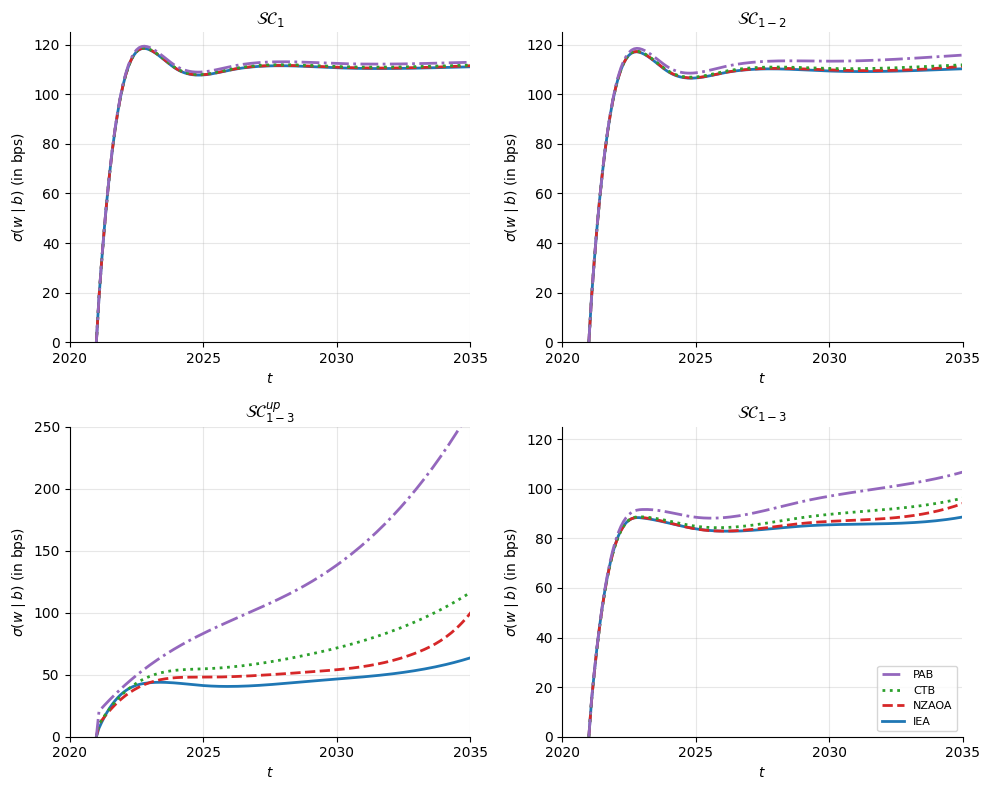

In [8]:
mat10a = sio.loadmat(f"{DATA_DIR}/chap11_net_zero10a.mat")
data_t = mat10a["all_t"].ravel().astype(float)
data_Risk = mat10a["all_sigma_x"]  # (nT=30, nPathway=4, nScope=4)

x_grid = np.arange(2021, 2050 + 1e-9, 0.1)
tol = 1e-1

y_by_scope_10b = []
for scope in range(4):
    data_Risk_Scope = data_Risk[:, :, scope]  # (nT, nPathway)
    y = np.zeros((len(x_grid), 4))
    for iter_ in range(4):
        y[:, iter_] = smoothing_spline_curve(
            data_t, data_Risk_Scope[:, iter_], x_grid, p=1 - tol, scale=1e4
        )
    y[0, :] = 0.0
    y_by_scope_10b.append(y)

plot_scope_grid(
    x_grid,
    y_by_scope_10b,
    r"$\sigma(w\mid b)$ (in bps)",
    ylims=[(0, 125), (0, 125), (0, 250), (0, 125)],
)

### 2. A second stock-level risk metric vs. time, by scope

Same 4-scope grid, this time reading the precomputed
`chap11_net_zero10c.mat` file's `all_results(6)` entry directly (index 5
in 0-based Python) -- the file holds 7 unlabeled entries and this is
simply the one used here, with no further documentation of what
distinguishes the other six. Values are scaled by 100 and halved
(`y = y/2`), with no further explanation of the metric beyond its axis
label $\mathcal{D}(w\mid b)$ -- reproduced literally rather than guessed
at.


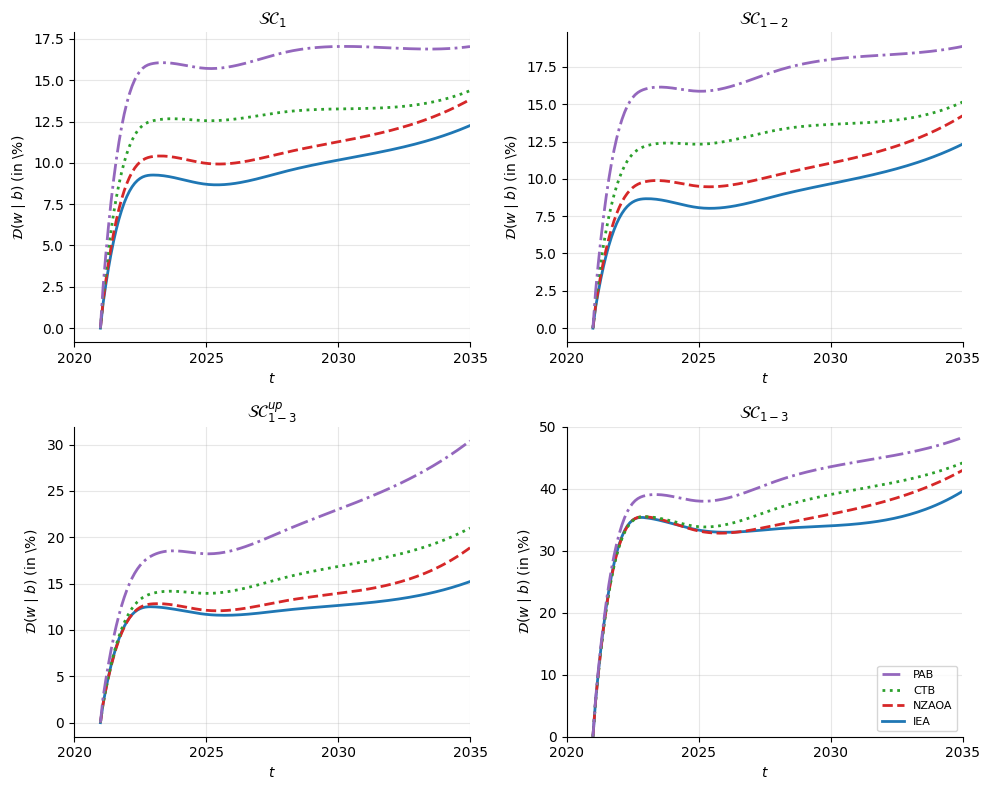

In [9]:
mat10c = sio.loadmat(f"{DATA_DIR}/chap11_net_zero10c.mat", struct_as_record=False, squeeze_me=True)
all_results = mat10c["all_results"]
entry = all_results[5]  # entry 6 of 7 (1-indexed)
data_t_c = entry.dates[:, 0, 0].astype(float)
data_D = entry.data  # (nT=15, nScope=4, nPathway=4)

y_by_scope_10c = []
for scope in range(4):
    data_D_Scope = data_D[:, scope, :]  # (nT, nPathway)
    y = np.zeros((len(x_grid), 4))
    for iter_ in range(4):
        y[:, iter_] = smoothing_spline_curve(
            data_t_c, data_D_Scope[:, iter_], x_grid, p=1 - tol, scale=100.0
        )
    y[0, :] = 0.0
    y = y / 2
    y_by_scope_10c.append(y)

plot_scope_grid(
    x_grid, y_by_scope_10c, r"$\mathcal{D}(w\mid b)$ (in \%)", ylims=[None, None, None, (0, 50)]
)

### What's not computed here

The stock-level re-optimization itself -- the actual tracking-error
minimization at real MSCI World stock level, along all four pathway
glide paths and all four emission scopes -- is not reproduced in this
notebook. It requires two inputs that aren't available: a stock-level
MSCI World holdings/emissions panel, and a precomputed pathway-target
file feeding the glide-path grid. The precomputed `chap11_net_zero10a.mat`
output used in the section above shows that this compute step has been
run successfully at some point against the underlying data, but the raw
inputs needed to reproduce it here aren't available.

Similarly, whatever produced the `chap11_net_zero10c.mat` file's
`all_results` array (a set of 7 unlabeled entries) isn't available
either -- only the precomputed output and the plot built from it above
are reproducible here.
